# Libraries import

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Dataset load

In [37]:
iris = load_iris()

In [38]:
x = iris.data
y = iris.target

In [39]:
print("Dataset loaded successfully!")
print("Total rows:", x.shape[0])
print("Total features:", x.shape[1])
print("Flower species:", iris.target_names)

Dataset loaded successfully!
Total rows: 150
Total features: 4
Flower species: ['setosa' 'versicolor' 'virginica']


# Dataset ko DataFrame 

In [40]:
df = pd.DataFrame(x, columns=iris.feature_names)

In [41]:
df["species"] = [iris.target_names[i] for i in y]

In [42]:
print(df.head(10))
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8  setosa  
9  setosa 

# Dataset ko Training or Testing

In [43]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 120
Testing samples: 30


# Machine Learning model

In [45]:
model = KNeighborsClassifier(n_neighbors=3)

In [46]:
model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [47]:
print("Model trained successfully!")

Model trained successfully!


# Model ki Accuracy

In [48]:
y_pred = model.predict(x_test)

In [49]:
accuracy = accuracy_score(y_test, y_pred)

In [50]:
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")

Model Accuracy: 100.0 %

Classification Report:



In [51]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# New Flower Species predict

In [52]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)

In [53]:
print(
    "Predicted Flower Species:",
    iris.target_names[prediction[0]]
)

Predicted Flower Species: setosa


# Graph

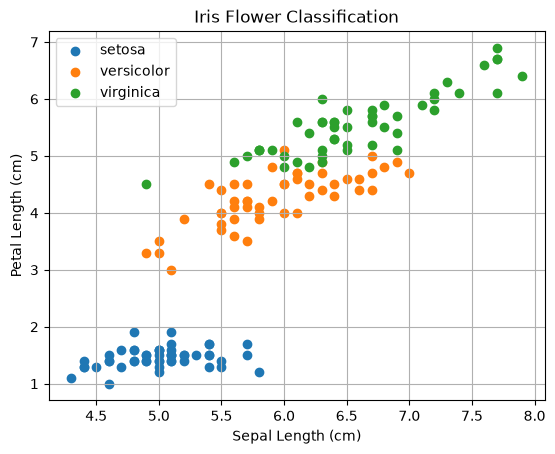

In [61]:
for species_id, species_name in enumerate(iris.target_names):
    plt.scatter(
        x[y == species_id, 0],
        x[y == species_id, 2],
        label=species_name
    )
    plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Flower Classification")
plt.legend()
plt.grid(True)
plt.show()

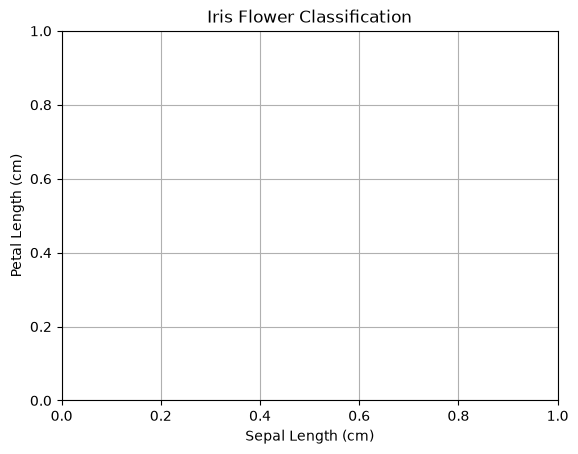

In [58]:
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Flower Classification")
plt.grid(True)
plt.show()


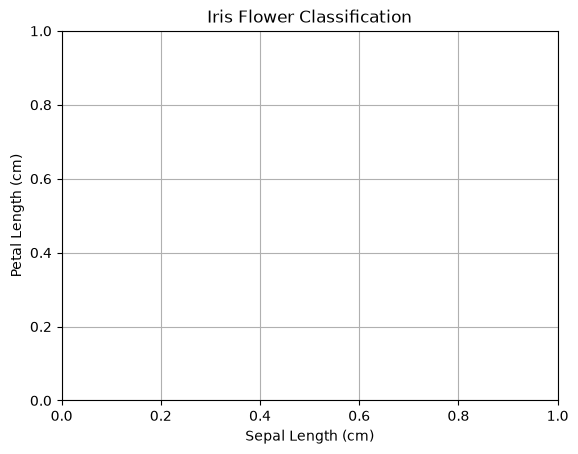

In [60]:
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Flower Classification")
plt.grid(True)
plt.show()

# Model ki Accuracy

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Split the dataset into training and testing data

In [10]:
iris = load_iris()
x = iris.data
y = iris.target

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Train the model

In [13]:
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Predict the flower species

In [14]:
y_pred = model.predict(X_test)

# Calculate accuracy

In [17]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


# Classification Report

In [18]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# Confusion Matrix

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix

In [20]:
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix

In [21]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

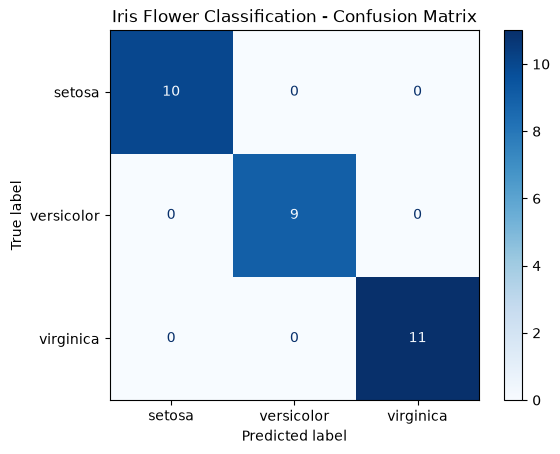

In [22]:
display.plot(cmap="Blues")
plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()

# Project ka Final Result

In [23]:

print("Project: Iris Flower Classification")
print("------------------------------------")
print("Algorithm: K-Nearest Neighbors (KNN)")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("Status: Project Completed Successfully")

Project: Iris Flower Classification
------------------------------------
Algorithm: K-Nearest Neighbors (KNN)
Model Accuracy: 100.00%
Status: Project Completed Successfully


In [24]:

print("======================================")
print("   IRIS FLOWER CLASSIFICATION PROJECT")
print("======================================")
print("Algorithm: K-Nearest Neighbors (KNN)")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("Dataset: Iris Dataset")
print("Classes: Setosa, Versicolor, Virginica")
print("Status: Project Completed Successfully")
print("======================================")


   IRIS FLOWER CLASSIFICATION PROJECT
Algorithm: K-Nearest Neighbors (KNN)
Model Accuracy: 100.00%
Dataset: Iris Dataset
Classes: Setosa, Versicolor, Virginica
Status: Project Completed Successfully


# New flower measurements

In [25]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict flower species

In [26]:
prediction = model.predict(new_flower)

# Display result

In [27]:
print("Predicted Flower Species:", iris.target_names[prediction[0]])

Predicted Flower Species: setosa


## Conclusion

The Iris Flower Classification project was completed successfully using Python and the K-Nearest Neighbors (KNN) algorithm. The Iris dataset was used to train and test the machine learning model. Data visualization, model accuracy evaluation, classification report, and confusion matrix were used to evaluate its performance. The model achieved 100% accuracy on the test dataset in this run and successfully predicted the species of a sample flower.

This project demonstrates how machine learning can be used to classify flowers based on their measurements.